# 07 — Formulação QUBO e validação contra o ótimo discreto
**Pergunta:** o problema de alocação discretizado pode ser escrito como QUBO e esse QUBO reproduz o ótimo discreto clássico?

**Discretização:** 4 grupos (urbano/irrigação × jul–set/out–dez); cada grupo escolhe uma fração da sua demanda em 2ᵇ níveis (b bits por grupo; b = 2 → {0, 1/3, 2/3, 1}; 8 qubits).

**Ponto metodológico central:** o objetivo exato (regra de racionamento + CVaR) **não é quadrático** nos bits. O QUBO aqui é um **substituto (surrogate) ajustado por mínimos quadrados** a todas as 2ⁿ avaliações exatas. Ele é uma **aproximação cuja qualidade é medida**, e só é viável porque a instância é pequena o bastante para enumerar. Instâncias: B e C com S₀ = 200 hm³ e demanda ×2 (as de escassez real, onde o plano importa), λ = 0,5, α = 0,8. Demanda, volume morto e pesos são hipóteses.

In [1]:
import sys, json; sys.path.insert(0, '..')
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from src.data.loaders import load_portal_volume
from src.hydrology.evaporation import load_power, penman_open_water_mm
from src.scenarios.generator import ScenarioGenerator
from src.scenarios import synthetic as S
from src.optimization.problem import make_instance
from src.optimization.classical.milp import solve_milp
from src.optimization import discrete as Dd
from src.optimization.qubo.surrogate import fit_qubo, qiskit_crosscheck, to_pauli_op
from src.evaluation.metrics import summarize

vol = load_portal_volume('../data/reserv-ors-capac-175236-portal-hidrologico-ce.csv')
met = load_power('../data/raw/meteo/nasa_power_oros_daily.json'); met['E_mm_day'] = penman_open_water_mm(met)
gen = ScenarioGenerator(vol, met)
CFGS = {'B': S.CONFIG_B, 'C': S.CONFIG_C}; LAM, ALPHA = 0.5, 0.8
INST = {k: make_instance(gen.inflow_sequences(c), c, 200, f'{k}_200_2', demand_scale=2) for k, c in CFGS.items()}

## 1. Enumeração exaustiva × MILP discreto × MILP contínuo
O **MILP discreto** (variável inteira de nível por grupo) deve coincidir com a enumeração: é uma verificação independente do código de enumeração e do modelo.

In [2]:
rows = []
for ck, inst in INST.items():
    cont = solve_milp(inst, LAM, ALPHA)
    for b in (1, 2, 3):
        dz = Dd.Discretization(b); df = Dd.enumerate_all(inst, dz, LAM, ALPHA); md = solve_milp(inst, LAM, ALPHA, discretization=dz)
        rows.append(dict(cfg=ck, bits_por_grupo=b, qubits=dz.n_bits, planos=2 ** dz.n_bits, J_enumeracao=df.J.min(), J_MILP_discreto=md['objective'],
                         dif_enum_milp=abs(df.J.min() - md['objective']), J_MILP_continuo=cont['objective'],
                         custo_discretizacao_pct=100 * (df.J.min() / cont['objective'] - 1), bits_otimos=df.bits[df.J.idxmin()]))
tab_disc = pd.DataFrame(rows); tab_disc.round(4)

,cfg,bits_por_grupo,qubits,planos,J_enumeracao,J_MILP_discreto,dif_enum_milp,J_MILP_continuo,custo_discretizacao_pct,bits_otimos
0,B,1,4,16,99.3167,99.3167,0.0,91.8901,8.0820,1101
1,B,2,8,256,93.8755,93.8755,0.0,91.8901,2.1605,11110001
2,B,3,12,4096,94.3707,94.3707,0.0,91.8901,2.6994,111111000001
3,C,1,4,16,80.1067,80.1067,0.0,76.3731,4.8886,1111
4,C,2,8,256,79.5423,79.5423,0.0,76.3731,4.1497,11110111
5,C,3,12,4096,77.0730,77.0730,0.0,76.3731,0.9164,111111011111


**E08 (parte clássica):** a discretização grossa custa pouco em relação ao contínuo, e os níveis não são aninhados (k/3 × k/7), então a perda não é monotônica em b.

## 2. Qualidade do QUBO substituto (8 qubits)

In [3]:
dz = Dd.Discretization(2); X = dz.all_bitstrings(); fits = {}
rows = []
for ck, inst in INST.items():
    df = Dd.enumerate_all(inst, dz, LAM, ALPHA); J = df.J.values
    for name, tau in (('sem pesos (principal)', None), ('ajuste local τ=20 (diagnóstico)', 20.0)):
        Q, d = fit_qubo(X, J, tau); fits[(ck, tau)] = (Q, d, J, df)
        rows.append(dict(cfg=ck, ajuste=name, R2=d['r2'], spearman=d['spearman'], RMSE=d['rmse'], parametros=d['n_params'],
                         gap_J_do_minimo_do_QUBO=d['gap_true_J'], posto_do_minimo_do_QUBO=d['rank_of_qubo_min_in_true'],
                         bits_otimo_real=df.bits[d['argmin_true']], bits_min_QUBO=df.bits[d['argmin_qubo']]))
tab_q = pd.DataFrame(rows); tab_q.round(3)

,cfg,ajuste,R2,spearman,RMSE,parametros,gap_J_do_minimo_do_QUBO,posto_do_minimo_do_QUBO,bits_otimo_real,bits_min_QUBO
0,B,sem pesos (principal),0.985,0.991,3.982,37,5.441,2,11110001,11110011
1,B,ajuste local τ=20 (diagnóstico),0.970,0.987,5.532,37,0.000,1,11110001,11110001
2,C,sem pesos (principal),0.997,0.998,2.139,37,4.216,3,11110111,11111011
3,C,ajuste local τ=20 (diagnóstico),0.993,0.998,3.273,37,0.000,1,11110111,11110111


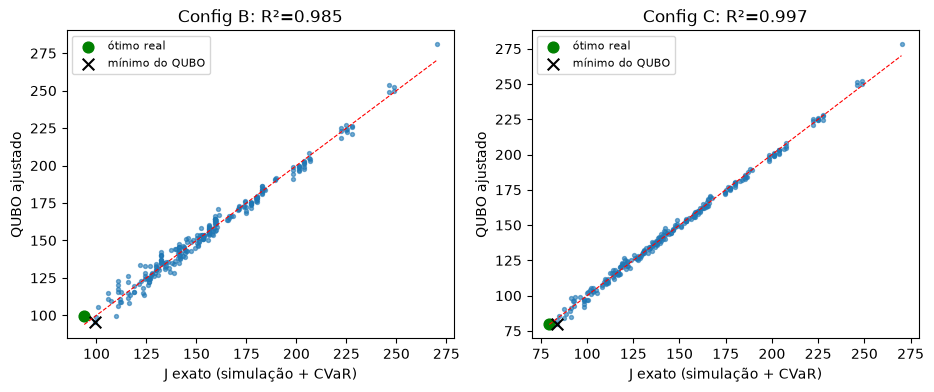

In [4]:
fig, axs = plt.subplots(1, 2, figsize=(11, 4))
for ax, ck in zip(axs, CFGS):
    Q, d, J, df = fits[(ck, None)]; q = Q.energy(X)
    ax.scatter(J, q, s=8, alpha=.6); lim = [J.min(), J.max()]; ax.plot(lim, lim, 'r--', lw=.8)
    ax.scatter([J[d['argmin_true']]], [q[d['argmin_true']]], c='g', s=60, label='ótimo real'); ax.scatter([J[d['argmin_qubo']]], [q[d['argmin_qubo']]], c='k', marker='x', s=70, label='mínimo do QUBO')
    ax.set_xlabel('J exato (simulação + CVaR)'); ax.set_ylabel('QUBO ajustado'); ax.set_title(f'Config {ck}: R²={d["r2"]:.3f}'); ax.legend(fontsize=8)
fig.savefig('../results/figures/07_qubo_fit.png', dpi=150, bbox_inches='tight')

## 3. Os planos escolhidos, em termos hidrológicos
O erro do QUBO deve ser lido em **qualidade hidrológica**, não só em energia.

In [5]:
rows = []
for ck, inst in INST.items():
    Q, d, J, df = fits[(ck, None)]
    for label, i in (('ótimo discreto real', d['argmin_true']), ('mínimo do QUBO', d['argmin_qubo'])):
        bits = X[i]; a = dz.decode(bits, inst); s = summarize(inst, a, ALPHA)
        rows.append(dict(cfg=ck, plano=label, bits=df.bits[i], J=J[i], deficit_urbano_pct=s['exp_deficit_urban_pct'], deficit_irrig_pct=s['exp_deficit_irrig_pct'],
                         perda_esp=s['exp_loss'], CVaR=s['cvar_loss'], armaz_final_esp=s['exp_final_storage_hm3'],
                         frac_grupos=str(np.round(dz.fractions(bits), 2).tolist())))
tab_plans = pd.DataFrame(rows); tab_plans.round(2)

,cfg,plano,bits,J,deficit_urbano_pct,deficit_irrig_pct,perda_esp,CVaR,armaz_final_esp,frac_grupos
0,B,ótimo discreto real,11110001,93.88,0.41,70.03,89.53,98.22,120.76,"[1.0, 1.0, 0.0, 0.67]"
1,B,mínimo do QUBO,11110011,99.32,6.37,62.08,87.97,110.67,113.51,"[1.0, 1.0, 0.0, 1.0]"
2,C,ótimo discreto real,11110111,79.54,8.70,27.73,47.67,111.41,121.86,"[1.0, 1.0, 0.67, 1.0]"
3,C,mínimo do QUBO,11111011,83.76,5.08,41.50,59.97,107.55,137.61,"[1.0, 1.0, 0.33, 1.0]"


## 4. Conferência do hamiltoniano
A conversão QUBO → Ising foi comparada com `qiskit_optimization.QuadraticProgram.to_ising()` em todos os 256 estados.

In [6]:
for ck in CFGS:
    Q = fits[(ck, None)][0]; print(ck, 'máx |diferença| vs qiskit-optimization:', f'{qiskit_crosscheck(Q):.2e}', '| termos de Pauli:', len(to_pauli_op(Q)[0]))
import os; os.makedirs('../results/qubo', exist_ok=True)
for (ck, tau), (Q, d, J, df) in fits.items():
    json.dump(dict(cfg=ck, tau=tau, const=Q.const, h=Q.h.tolist(), q=Q.q.tolist(), diagnostics={k: (float(v) if v is not None else None) for k, v in d.items()},
                   instance=dict(s0=200, demand_scale=2, lam=LAM, alpha=ALPHA, bits_per_group=2)), open(f'../results/qubo/qubo_{ck}_{"unweighted" if tau is None else "tau20"}.json', 'w'), indent=1)
tab_disc.to_csv('../results/exp07_discretization.csv', index=False); tab_q.to_csv('../results/exp07_qubo_fit.csv', index=False); tab_plans.to_csv('../results/exp07_selected_plans.csv', index=False)

B máx |diferença| vs qiskit-optimization: 8.53e-14 | termos de Pauli: 36
C máx |diferença| vs qiskit-optimization: 8.53e-14 | termos de Pauli: 36


## 5. Conclusão do experimento 07 (a preencher com os números acima no relatório, seção 4.7)